# 04 · Your first strategy: moving-average crossover

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/04_first_strategy_ma_crossover.ipynb)

*QM FinTech Society quant workshop · Led by **Adnan Salehin** (Lead SWE & VP, JPMorgan)*

You now know how to measure a result (notebook 01), how a backtest can lie (02) and how to limit losses (03). Time to test a real strategy, with those tools to hand.

**What you'll do (~60 min):**
1. Load ten years of real price data
2. Turn prices into returns
3. Build a trading signal from two moving averages
4. Backtest it and compare it with buy and hold
5. Check it the way notebook 02 taught you: trade count and costs
6. Test it fairly with a walk-forward
7. Change it and make it yours

Cells marked **✏️ Try it** are for you to edit and re-run.

> **Running in Google Colab?** If Colab warns that this notebook wasn't written by Google, click **Run anyway**. Then use **File → Save a copy in Drive** so your changes are kept.

## Setup

This first cell gets the notebook ready. In Google Colab it downloads the workshop code and price data from GitHub; on a laptop it simply finds them. It also imports pandas (tables of data) and matplotlib (charts), which the rest of the notebook uses.

In [1]:
# ▶ Setup — run this cell first.
# In Google Colab it downloads the workshop repo; on your laptop it just finds the code.
import os, subprocess, sys

REPO = "qm-fintech-quant-workshop"
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", f"https://github.com/kolyamkl/{REPO}.git"], check=True)
    os.chdir(REPO)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # the code lives one folder up from notebooks/
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# Re-load your edited .py files automatically (handy when you change strategies/template.py).
# Skipped where it can't run (Colab's IPython version doesn't support it on Python 3.13).
try:
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except ImportError:
    pass

import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.precision", 4)

## 1. Load the data

All prices live in one file, `data/prices.csv`: one row per ticker per day. Let's open it with plain pandas first so nothing is hidden.

The cell below reads the CSV into a pandas **DataFrame** (a table) and turns the `Date` column into real dates. `df.head()` shows the first five rows.

In [2]:
df = pd.read_csv("data/prices.csv", parse_dates=["Date"])
df.head()

,Date,Ticker,Open,High,Low,Close,Volume
0,2016-01-04,AAPL,23.0726,23.6932,22.9354,23.6887,270597600
1,2016-01-05,AAPL,23.7786,23.8011,23.0276,23.0951,223164000
2,2016-01-06,AAPL,22.6116,23.0186,22.4565,22.6431,273829600
3,2016-01-07,AAPL,22.1889,22.5149,21.6829,21.6874,324377600
4,2016-01-08,AAPL,22.1596,22.2856,21.7572,21.8021,283192000


How big is the dataset, and what's in it? `df.shape` prints the number of rows and columns, and the second line lists every ticker in the file, A to Z. These are the tickers you can use anywhere in the workshop.

In [3]:
print(df.shape)
print(sorted(df["Ticker"].unique()))

(64992, 7)
['AAPL', 'AMZN', 'DIA', 'GLD', 'GOOGL', 'IEF', 'IWM', 'JNJ', 'JPM', 'MSFT', 'PG', 'QQQ', 'SPY', 'TLT', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY', 'XOM']


The table mixes all tickers together, but a strategy trades one at a time. This cell keeps only SPY's rows (SPY is an ETF that holds the S&P 500 companies) and makes the date the index, so every row is labelled by its day. `.tail()` shows the last five days.

In [4]:
spy = df[df["Ticker"] == "SPY"].set_index("Date")
spy.tail()

,Ticker,Open,High,Low,Close,Volume
Date,,,,,,
2026-10-05,SPY,769.69,776.61,769.63,774.83,44840200
2026-10-06,SPY,778.15,781.62,777.96,779.09,36054300
2026-10-07,SPY,775.77,779.10,773.61,777.22,30989200
2026-10-08,SPY,774.86,777.09,770.44,773.93,40431100
2026-10-09,SPY,776.24,779.42,775.14,778.57,22596500


Picking one ticker is needed so often that the repo has a helper, `load_prices`, that does the same job in one line. This cell imports it (plus `run_backtest`, which we use in section 4) and plots SPY's closing price over the whole period. The prices are adjusted for splits and dividends, so the line shows the real growth.

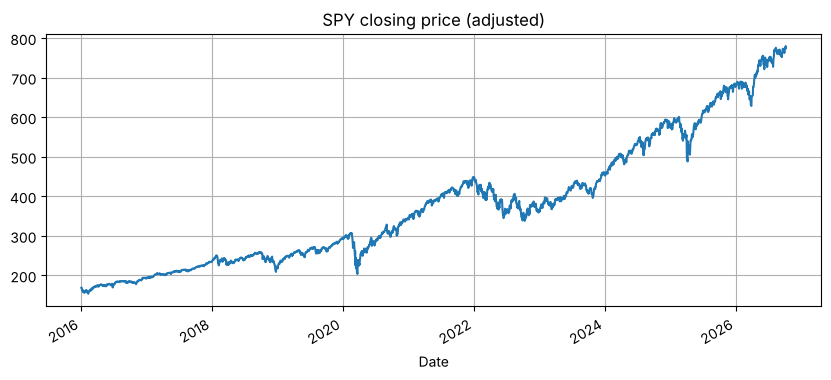

In [5]:
from backtester import load_prices, run_backtest

spy = load_prices("SPY")
spy["Close"].plot(figsize=(10, 4), title="SPY closing price (adjusted)", grid=True)
plt.show()

**✏️ Try it:** change `"SPY"` above to `"AAPL"`, `"XLE"` or `"GLD"` and re-run. Then set it back to SPY.

## 2. From prices to returns

Traders care about **returns** — percentage changes — not price levels: +1% means the same thing for a $10 stock and a $500 stock.

`pct_change()` calculates each day's percentage change in the closing price. `describe()` then summarises all those daily returns: how many there are, the average, how spread out they are (`std`) and the extremes.

In [6]:
returns = spy["Close"].pct_change()
returns.describe()

count    2707.0000
mean        0.0006
std         0.0111
min        -0.1094
25%        -0.0036
50%         0.0007
75%         0.0059
max         0.1050
Name: Close, dtype: float64

Averages hide the extremes, so let's find them. `idxmin()` and `idxmax()` give the dates of the worst and the best daily return, and the f-strings print them as percentages. Can you guess what happened in the markets on those days?

In [7]:
print(f"Worst day: {returns.idxmin():%Y-%m-%d}  {returns.min():.1%}")
print(f"Best day:  {returns.idxmax():%Y-%m-%d}  {returns.max():.1%}")

Worst day: 2020-03-16  -10.9%
Best day:  2025-04-09  10.5%


Daily returns **compound**: two +1% days in a row give +2.01%, not +2%. The code adds 1 to each return and multiplies them all together with `cumprod()`, which gives the value of $1 invested on the first day. The very first return is empty (there is no day before it), so `fillna(0)` counts it as 0%.

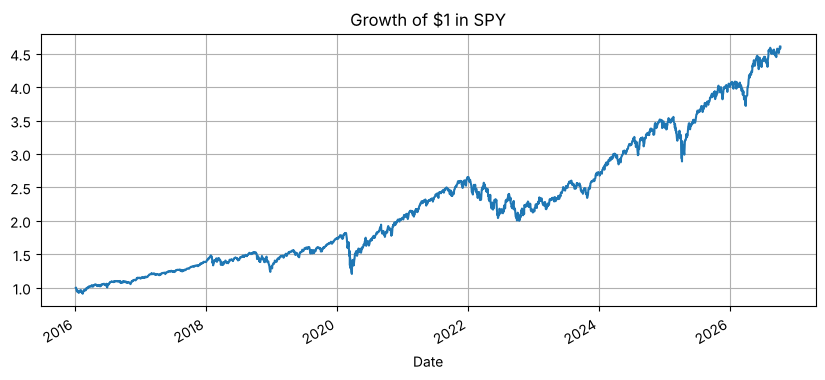

In [8]:
growth = (1 + returns.fillna(0)).cumprod()
growth.plot(figsize=(10, 4), title="Growth of $1 in SPY", grid=True)
plt.show()

## 3. A signal: the moving-average crossover

A **moving average** is the average of the last *N* closing prices. A short one (50 days) reacts quickly; a long one (200 days) shows the slow trend.

**The rule:** hold SPY while the 50-day average is above the 200-day average (an uptrend); otherwise sit in cash.

A 200-day average needs 200 days of prices before it exists, so the strategy sits in cash for that first stretch. This is called the **warm-up**.

The cell below calculates both averages with `rolling(N).mean()`, which averages the last N closes on every day. It then draws them on top of the price so you can see where they cross.

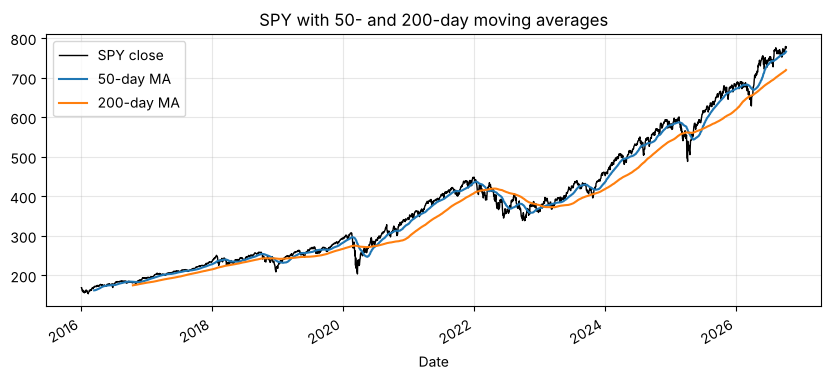

In [9]:
fast_ma = spy["Close"].rolling(50).mean()
slow_ma = spy["Close"].rolling(200).mean()

fig, ax = plt.subplots(figsize=(10, 4))
spy["Close"].plot(ax=ax, label="SPY close", color="black", linewidth=1)
fast_ma.plot(ax=ax, label="50-day MA")
slow_ma.plot(ax=ax, label="200-day MA")
ax.set_title("SPY with 50- and 200-day moving averages")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

Now turn the two averages into a decision for every day. `fast_ma > slow_ma` gives True or False, and `.astype(int)` turns that into `1` (hold SPY) or `0` (cash); during the warm-up the comparison is False, so those days are cash. `value_counts()` shows how many days the strategy spends in each state.

In [10]:
position = (fast_ma > slow_ma).astype(int)
position.value_counts()

Close
1    2107
0     601
Name: count, dtype: int64

The repo keeps this exact logic as a reusable function in `strategies/ma_crossover.py` (open the file and see). This cell runs it with the same 50/200 settings and checks that it gives the same position on every single day. `True` means they match.

In [11]:
from strategies import ma_crossover

positions = ma_crossover(spy, fast=50, slow=200)
bool((positions == position).all())

True

## 4. Backtest it

`run_backtest` turns positions into a portfolio value, starting from $10,000 and paying 5 bps (0.05%) every time the position changes.

One crucial detail: a signal computed from **today's** close can only earn **tomorrow's** return. The engine shifts positions by one day for you — open `backtester/engine.py` and find the comment *"THE MOST IMPORTANT LINE IN THIS REPO"*.

The cell below runs the backtest and prints `summary()`: the strategy's results next to simply buying and holding SPY over the same dates.

In [12]:
result = run_backtest(spy, positions, cost_bps=5)
result.summary()

,Strategy,Buy & hold
Total return,191.8%,360.6%
Annual return (CAGR),10.5%,15.3%
Annual volatility,14.7%,17.7%
Sharpe ratio,0.75,0.89
Max drawdown,-33.7%,-33.7%
Number of trades,5,—
Win rate,80.0%,—


**Read the table:** did the strategy beat buy-and-hold on total return? On Sharpe ratio? On max drawdown? Trend following is often described as *"earn a bit less, but lose less in crashes"*. Compare the two max drawdowns: if they are similar, that's a lesson too. A moving average reacts slowly, so in a very fast crash the price can fall a long way before the averages cross. Whether a strategy is "better" depends on what you care about.

Numbers are easier to judge as pictures. `result.plot()` draws two charts: the top one shows what $10,000 grew to with the strategy and with buy & hold, and the bottom one shows the **drawdown**, how far each was below its previous high.

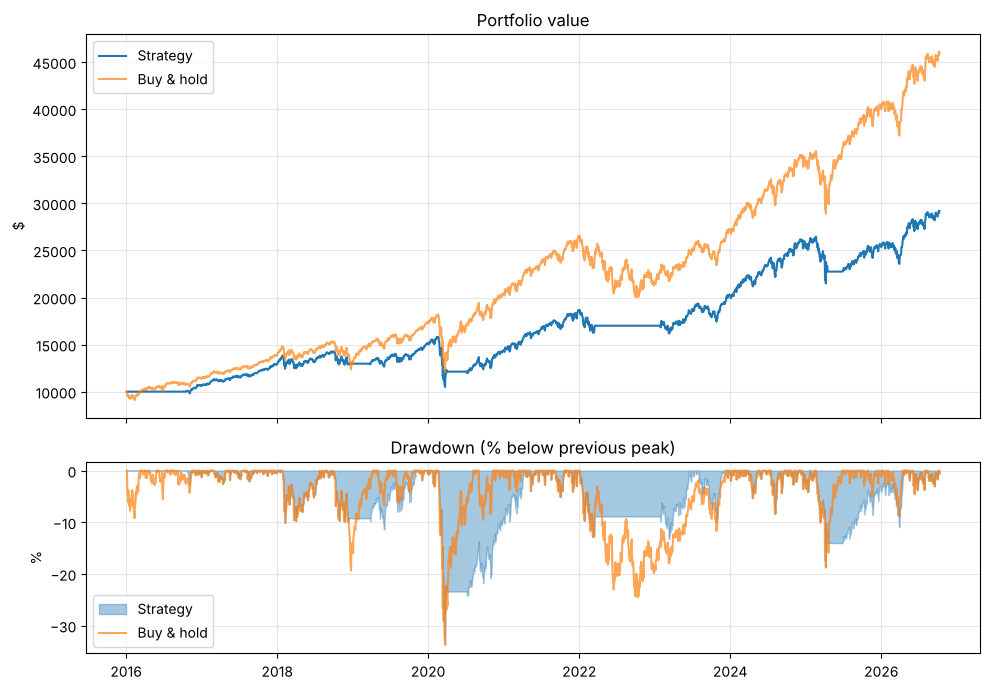

In [13]:
result.plot()

This chart shows *when* the strategy traded. `plot_signals` draws the SPY price with both moving averages and marks every buy (green ▲) and sell (red ▼). The trades should line up with the moments the two averages cross.

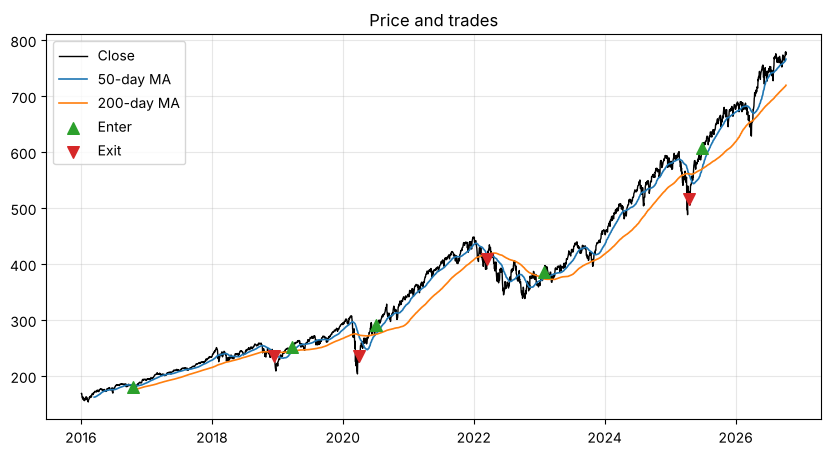

In [14]:
from backtester.plotting import plot_signals

plot_signals(spy, result, overlays={"50-day MA": fast_ma, "200-day MA": slow_ma})

And here is every trade as a table. Each row is one round trip: entry and exit dates and prices, and the return before costs. A trade with `open` = True was still held when the data ended, so it is valued at the last close.

In [15]:
result.trades

,entry_date,exit_date,direction,entry_price,exit_price,return,open
0,2016-10-17,2018-12-12,long,181.3716,235.5116,0.2985,False
1,2019-03-26,2020-03-31,long,251.9662,235.7402,-0.0644,False
2,2020-07-06,2022-03-16,long,291.2526,408.8679,0.4038,False
3,2023-01-26,2025-04-16,long,386.0568,517.0829,0.3394,False
4,2025-06-27,2026-10-09,long,606.6648,778.5700,0.2834,True


**✏️ Try it:** change `fast` and `slow` in the `ma_crossover(...)` cell (e.g. 20 and 100), then re-run the cells below it. What changes — the number of trades? the drawdown?

## 5. Check it the way notebook 02 taught you

**Count the trades first.** A result built on a handful of trades proves little, and a strategy that trades constantly pays for it in costs.

In [16]:
print(f"Trades: {int(result.metrics['Number of trades'])}   Win rate: {result.metrics['Win rate']:.0%}")

Trades: 5   Win rate: 80%


Only a few trades in ten years. Notebook 02 showed that with five trades, roughly one strategy in five with no skill at all would still show a win rate of 80% or more. So the high win rate says very little. Hold the trade count in mind for everything that follows.

### Costs on a real strategy

Every trade costs money (fees, plus the gap between buy and sell prices). A strategy that trades rarely barely notices; one that trades often can be eaten alive. Compare the slow 50/200 crossover with a fast 5/20 one.

The cell below backtests both settings at four trading costs, from 0 to 50 bp, and shows the total return of each in one table.

In [17]:
rows = []
for fast_n, slow_n in [(50, 200), (5, 20)]:
    pos = ma_crossover(spy, fast=fast_n, slow=slow_n)
    for cost in [0, 5, 20, 50]:
        r = run_backtest(spy, pos, cost_bps=cost)
        rows.append({"MA": f"{fast_n}/{slow_n}", "cost (bps)": cost, "total return": r.metrics["Total return"]})

pd.DataFrame(rows).pivot(index="cost (bps)", columns="MA", values="total return").style.format("{:.1%}")

MA,5/20,50/200
cost (bps),,
0,237.5%,193.2%
5,214.6%,191.8%
20,154.6%,187.9%
50,66.6%,180.2%


Why do costs hurt one setting more than the other? This cell counts how many trades each one made over the whole period. Every trade pays the cost, so more trades mean a bigger bill.

In [18]:
for fast_n, slow_n in [(50, 200), (5, 20)]:
    n = run_backtest(spy, ma_crossover(spy, fast=fast_n, slow=slow_n)).metrics["Number of trades"]
    print(f"{fast_n}/{slow_n}: {n} trades")

50/200: 5 trades
5/20: 71 trades


## 6. Test it fairly: a walk-forward

Notebook 02 showed why the best row of a tuning table cannot be trusted, and how a **walk-forward** gives several fair exams: tune on three years, test on the next year, slide forward and repeat. Here it chooses the fast and slow averages using only the past before each test year.

In [19]:
from backtester.honesty import walk_forward

settings = [{"fast": f, "slow": s} for f in [10, 20, 50] for s in [100, 150, 200]]
folds = walk_forward(spy, lambda prices, fast, slow: ma_crossover(prices, fast=fast, slow=slow), settings, train_days=756, test_days=252)
folds.style.format({
    "train from": "{:%Y-%m-%d}", "test from": "{:%Y-%m-%d}", "test to": "{:%Y-%m-%d}",
    "train Sharpe": "{:.2f}", "test Sharpe": "{:.2f}", "test return": "{:.1%}", "buy and hold test return": "{:.1%}",
})

,train from,test from,test to,chosen,train Sharpe,test Sharpe,test return,buy and hold test return
0,2016-01-04,2019-01-04,2020-01-03,"fast=20, slow=200",1.09,1.50,17.5%,30.2%
1,2017-01-03,2020-01-06,2021-01-04,"fast=20, slow=200",1.22,-0.45,-14.5%,16.1%
2,2018-01-03,2021-01-05,2022-01-03,"fast=10, slow=100",0.86,2.00,28.0%,30.4%
3,2019-01-04,2022-01-04,2023-01-04,"fast=10, slow=100",1.48,-2.24,-19.6%,-18.3%
4,2020-01-06,2023-01-05,2024-01-05,"fast=10, slow=100",0.58,1.07,12.1%,25.2%
5,2021-01-05,2024-01-08,2025-01-07,"fast=50, slow=200",0.99,1.88,25.6%,25.6%
6,2022-01-04,2025-01-08,2026-01-09,"fast=50, slow=200",0.94,0.17,1.4%,19.1%


Join the test years together and compare with buy and hold over the same years. This is the number you could actually have earned by following the process.

In [20]:
stitched = (1 + folds["test return"]).prod() - 1
held = (1 + folds["buy and hold test return"]).prod() - 1
print(f"Walk-forward crossover, test years joined: {stitched:.1%}")
print(f"Buy and hold, same years:                  {held:.1%}")

Walk-forward crossover, test years joined: 47.7%
Buy and hold, same years:                  201.4%


**Read it honestly.** Compare the stitched walk-forward result with buy and hold over the same years, and look back at the drawdown row in section 4. The 50/200 crossover had the same worst fall as buy and hold (-33.7%): it is slow to react, so in a fast crash such as March 2020 the averages cross late. And it paid for being out of the market by missing part of the rises. Whether that trade is worth it depends on what you care about.

Survivorship matters too: AAPL, MSFT and AMZN are in this data because they became giants. Testing on today's winners flatters any strategy.

**✏️ Try it:** change `test_days=252` to `126` in the walk-forward. Do you get more test periods? Are the results steadier?

## 7. Your turn

Some things to try:
- Run the crossover on other tickers: `QQQ`, `XLE`, `TLT`, `GLD`…
- Find settings that work across **many** tickers, not just one.
- Write your own rule in the cell below. No files to edit: change the function and re-run.

More exercises (easy → hard) are in [`docs/resources.md`](https://github.com/kolyamkl/qm-fintech-quant-workshop/blob/main/docs/resources.md). Want to keep your strategy as a file? Use `strategies/template.py`.

The example below is a simple **momentum** rule: hold SPY when today's close is higher than it was 20 days ago. The last two lines backtest your function on SPY and print the same summary table as before.

In [21]:
# ✏️ Try it: your own strategy. Return 1 = hold, 0 = cash, -1 = short, one value per day.
def my_strategy(prices):
    close = prices["Close"]
    # Example (momentum): hold when the price is higher than 20 days ago. Replace with your idea.
    position = (close > close.shift(20)).astype(int)
    return position


my_result = run_backtest(spy, my_strategy(spy))
my_result.summary()

,Strategy,Buy & hold
Total return,184.9%,360.6%
Annual return (CAGR),10.2%,15.3%
Annual volatility,10.5%,17.7%
Sharpe ratio,0.98,0.89
Max drawdown,-14.2%,-33.7%
Number of trades,103,—
Win rate,47.6%,—


**Be suspicious of a good result.** The example rule looks better than buy and hold on Sharpe ratio and on the worst fall. But it made 103 trades, you tried one idea and looked at the whole history, and nothing here was tested fairly. Notebook 02's tools (a train/test split, a walk-forward, costs) are how you would find out whether it is real.

### Next: a strategy that bets the opposite way

RSI mean reversion, and a straight answer to "does it beat buy and hold?"

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/05_second_strategy_rsi.ipynb) `05_second_strategy_rsi.ipynb`